In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()


# BALLADEER — 02. Auditoría (pasos 2.1 a 2.6 y 2.10)

Plan experimental v02 (`experiments-plan-experimental-mil-creda-sobre-balladeer-v02.md`), secciones 2.1–2.6, 2.10 y 10.1.

**Esta auditoría mide y marca; no excluye nada.** Donde el plan declara un criterio sin número (umbral de fracción perdida, de interpolación, de duración, piso de cardinalidad, corte de varianza o espectral), se muestra la distribución y no se inventa un corte. Las marcas que sí aparecen son las que no necesitan ningún número que el plan no haya dado ("alguna muestra en el riel", "varianza cero", "un hueco mayor que una ventana de 4 s", "alguna ventana bajo el 90 % declarado por el data paper").

Cada registro se leyó una sola vez (`MIL_CREDA_EEG.defect_log.run_audit`) y su resumen quedó en `MIL-CREDA/Results/audit/records/`; este cuaderno lee ese caché y no vuelve a abrir los 58 GB.

In [2]:
# El repositorio lo resolvió la celda de arriba; ésta sólo lo usa.
import sys
import json

REPOSITORY = ROOT
sys.path.insert(0, str(REPOSITORY / "src"))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from MIL_CREDA_EEG import (audit_channels, audit_contact, audit_plots, audit_rate, defect_log,
                       inventory, modality)

%matplotlib inline
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

RAW = REPOSITORY / inventory.RAW_RELATIVE
OUT = REPOSITORY / "MIL-CREDA" / "Results" / "audit"
FIG = OUT / "figures"
print("intérprete:", sys.executable)
assert str(REPOSITORY / ".venv") in sys.executable, "el kernel no es el venv del repositorio"

records = defect_log.run_audit(RAW, OUT, workers=4)   # lee el caché; calcula solo lo que falte
rec = defect_log.classify_records(defect_log.records_frame(records))
chan = defect_log.channels_frame(records)
rec.to_csv(OUT / "records.csv", index=False)
chan.to_csv(OUT / "channels.csv", index=False)
demo = inventory.load_demographics(RAW)
lab = demo.set_index("subject")["label"]
rec["label"] = rec["subject"].map(lab)
chan["label"] = chan["subject"].map(lab)
print("registros auditados:", len(rec), "| legibles:", int(rec["readable"].sum()))
rec.groupby(["family", "device"]).size().rename("registros").to_frame()

intérprete: /Users/diego/Proyectos/papersmith-ai/implementations/Domain_Adaptation/.venv/bin/python


registros auditados: 683 | legibles: 683


registros
family device             
CGX    CGX             420
EMOTIV EPOCPLUS        118
       EPOCX           145

## 2.1 Filtro de modalidad

Cada columna de cada archivo EEG va a uno de tres destinos: **señal** (entra al codificador), **metadata de auditoría** (la usan los pasos 2.2–2.6) o **descarte**.

**Qué son las columnas `.md.pm.bp` de Emotiv.** EmotivPRO nombra la exportación por los flujos que agregó al EEG crudo: `md` = datos de movimiento (`MOT.*`), `pm` = métricas de rendimiento (`PM.*`, puntajes propietarios como atención/foco, estrés, relajación) y `bp` = potencia por banda (`POW.*`, calculada por el software). Cada fila es una muestra de EEG; los flujos lentos se escriben solo en las filas donde se actualizan. `PM.*` y `POW.*` se descartan: no son reproducibles fuera de ese software, no tienen contraparte en CGX, y `PM.Attention`/`PM.Focus` es un puntaje propietario de atención, circular para clasificar un trastorno de atención.

In [3]:
rows = []
for path in sorted({r["path"] for r in records}):
    for row in modality.column_table(RAW / path):
        rows.append({**row, "path": path})
cols = pd.DataFrame(rows)
print("columnas sin clasificar en todo el release:", int((cols["destination"] == "unclassified").sum()))
per_file = cols.groupby(["path", "family", "destination"]).size().unstack(fill_value=0)
summary = per_file.groupby("family").agg(["min", "max"])
cols.drop_duplicates(["family", "column"]).to_csv(OUT / "column_destinations.csv", index=False)
summary

columnas sin clasificar en todo el release: 0


destination audit     discard      signal    
              min max     min  max    min max
family                                       
CGX             5   5       4    4     29  29
EMOTIV         35  36      88  119     14  14

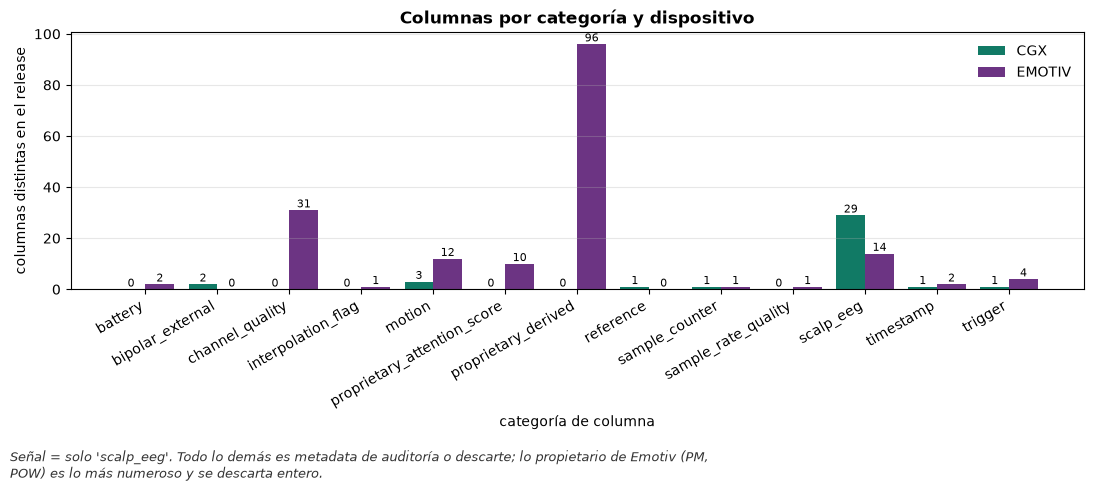

,family,category,columnas distintas,destino
0,CGX,bipolar_external,2,audit
2,CGX,reference,1,audit
3,CGX,sample_counter,1,audit
5,CGX,timestamp,1,audit
1,CGX,motion,3,discard
6,CGX,trigger,1,discard
4,CGX,scalp_eeg,29,signal
8,EMOTIV,channel_quality,31,audit
9,EMOTIV,interpolation_flag,1,audit
13,EMOTIV,sample_counter,1,audit


In [4]:
tab = (cols.drop_duplicates(["family", "column"]).groupby(["family", "category"]).size()
       .rename("columnas distintas").reset_index())
tab["destino"] = tab.apply(lambda r: modality.classify_column(r["family"], cols[(cols.family == r.family) & (cols.category == r.category)].column.iloc[0])[0], axis=1)
pivot = tab.pivot_table(index="category", columns="family", values="columnas distintas", fill_value=0)
fig = audit_plots.grouped_bar(pivot, "Columnas por categoría y dispositivo", "categoría de columna",
    "columnas distintas en el release",
    "Señal = solo 'scalp_eeg'. Todo lo demás es metadata de auditoría o descarte; "
    "lo propietario de Emotiv (PM, POW) es lo más numeroso y se descarta entero.", figsize=(11, 4.5))
audit_plots.save(fig, "02_2.1_columnas_por_categoria", FIG); plt.show()
tab.sort_values(["family", "destino"])

In [5]:
variants = cols[cols.family == "EMOTIV"].groupby("path")["column"].apply(tuple).value_counts()
print("variantes de cabecera Emotiv:", len(variants))
for k, (cols_tuple, n) in enumerate(variants.items()):
    names = set(cols_tuple)
    print(f"  variante {k}: {n} archivos, {len(cols_tuple)} columnas, "
          f"OriginalTimestamp={'OriginalTimestamp' in names}, PM.Attention={any(c.startswith('PM.Attention') for c in names)}, "
          f"PM.Focus={any(c.startswith('PM.Focus') for c in names)}, PM={any(c.startswith('PM.') for c in names)}")
print("las 14 columnas de señal son las mismas en todas:", 
      len({tuple(c for c in v if modality.classify_column('EMOTIV', c)[0] == 'signal') for v in variants.index}) == 1)
streams = pd.Series([";".join(r["export_streams"]) for r in records if r.get("export_streams") is not None]).value_counts()
streams

variantes de cabecera Emotiv: 5
  variante 0: 145 archivos, 169 columnas, OriginalTimestamp=True, PM.Attention=True, PM.Focus=False, PM=True
  variante 1: 81 archivos, 169 columnas, OriginalTimestamp=True, PM.Attention=False, PM.Focus=True, PM=True
  variante 2: 35 archivos, 168 columnas, OriginalTimestamp=False, PM.Attention=True, PM.Focus=False, PM=True
  variante 3: 1 archivos, 138 columnas, OriginalTimestamp=True, PM.Attention=False, PM.Focus=False, PM=False
  variante 4: 1 archivos, 168 columnas, OriginalTimestamp=False, PM.Attention=False, PM.Focus=True, PM=True
las 14 columnas de señal son las mismas en todas: True


motion_data;performance_metrics;band_power    262
motion_data;band_power                          1
Name: count, dtype: int64

## 2.2 Auditoría de tasa de muestreo

Por registro. La tasa efectiva sale de las marcas de tiempo (y, corregida, del contador). Es **defecto duro** (regla declarada completa) una tasa fuera del menú del fabricante (Emotiv: 128 y 256 Hz) o distinta de la nominal del registro. Sin tolerancia inventada: la tasa efectiva se asigna a la entrada del menú más cercana (en escala logarítmica) y su razón a la nominal al más cercano entre ½, 1 y 2. Para CGX el plan no declara menú; se usa la nominal del data paper (500 Hz).

Predicción del plan (§10.1): todos los registros Emotiv a la tasa baja (128 Hz).

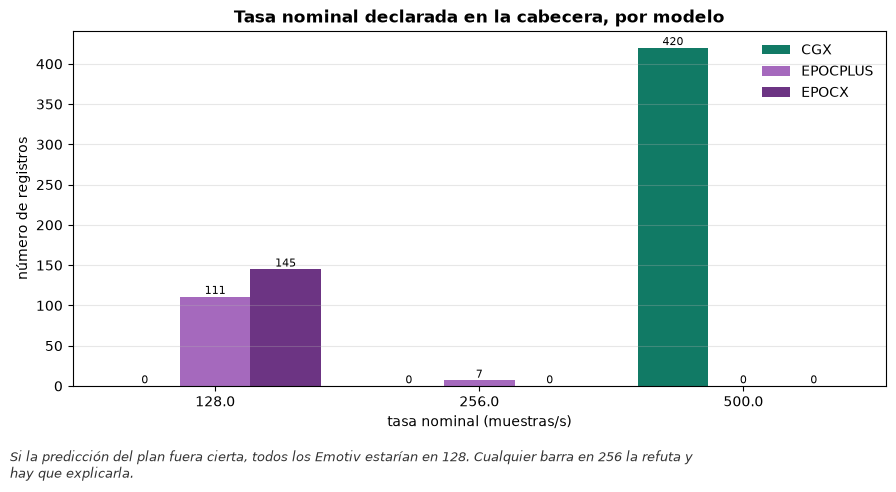

nominal_rate  128.0  256.0  500.0
device                           
CGX               0      0    420
EPOCPLUS        111      7      0
EPOCX           145      0      0
                                           record_id   device       condition
UB0101__AttentionRobotsDesktop__1698334795__EPOCPLUS EPOCPLUS   Robots/EMOTIV
UB0103__AttentionRobotsDesktop__1698683183__EPOCPLUS EPOCPLUS   Robots/EMOTIV
              UB0103__Cognifit__1698682406__EPOCPLUS EPOCPLUS Cognifit/EMOTIV
UB0109__AttentionRobotsDesktop__1698403223__EPOCPLUS EPOCPLUS   Robots/EMOTIV
              UB0109__Cognifit__1698405782__EPOCPLUS EPOCPLUS Cognifit/EMOTIV
UB0111__AttentionRobotsDesktop__1698421057__EPOCPLUS EPOCPLUS   Robots/EMOTIV
              UB0111__Cognifit__1698420181__EPOCPLUS EPOCPLUS Cognifit/EMOTIV


In [6]:
ok = rec[rec["readable"]]
nominal = ok.groupby(["device", "nominal_rate"]).size().unstack(fill_value=0)
fig = audit_plots.grouped_bar(nominal.T, "Tasa nominal declarada en la cabecera, por modelo",
    "tasa nominal (muestras/s)", "número de registros",
    "Si la predicción del plan fuera cierta, todos los Emotiv estarían en 128. Cualquier barra en 256 la refuta y hay que explicarla.")
audit_plots.save(fig, "02_2.2_tasa_nominal_por_modelo", FIG); plt.show()
print(nominal)
print(ok[ok.nominal_rate == 256][["record_id", "device", "condition"]].to_string(index=False))

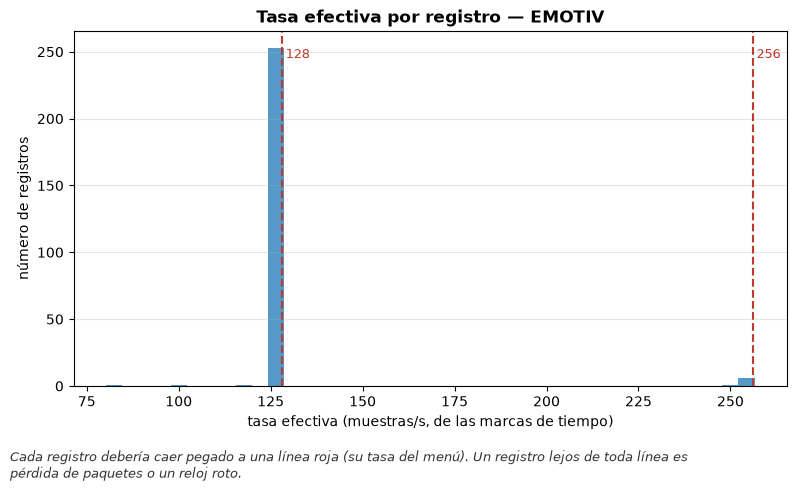

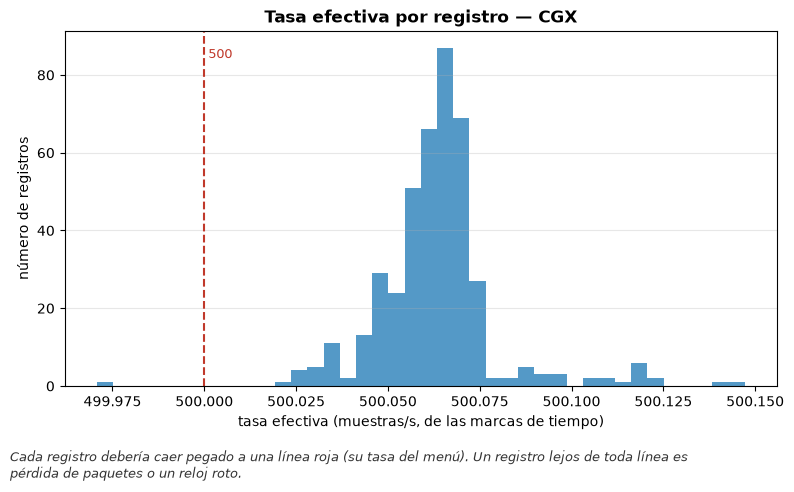

,count,mean,std,min,1%,50%,99%,max
device,,,,,,,,
CGX,420.0,0.000126,0.000033,-0.000058,0.000053,0.000127,0.000238,0.000294
EPOCPLUS,118.0,0.000264,0.007814,-0.066355,-0.025849,0.002177,0.002254,0.002271
EPOCX,145.0,-0.004179,0.036395,-0.373117,-0.141122,0.000532,0.000577,0.000577


In [7]:
for family, nominal_lines in (("EMOTIV", {"128": 128, "256": 256}), ("CGX", {"500": 500})):
    sub = ok[ok.family == family]
    fig = audit_plots.hist(sub["effective_rate"], f"Tasa efectiva por registro — {family}",
        "tasa efectiva (muestras/s, de las marcas de tiempo)", "número de registros",
        "Cada registro debería caer pegado a una línea roja (su tasa del menú). Un registro lejos de toda línea es pérdida de paquetes o un reloj roto.",
        bins=40, lines=nominal_lines)
    audit_plots.save(fig, f"02_2.2_tasa_efectiva_{family}", FIG); plt.show()
dev = ok.groupby("device")["relative_deviation"].describe(percentiles=[.01, .5, .99])
dev

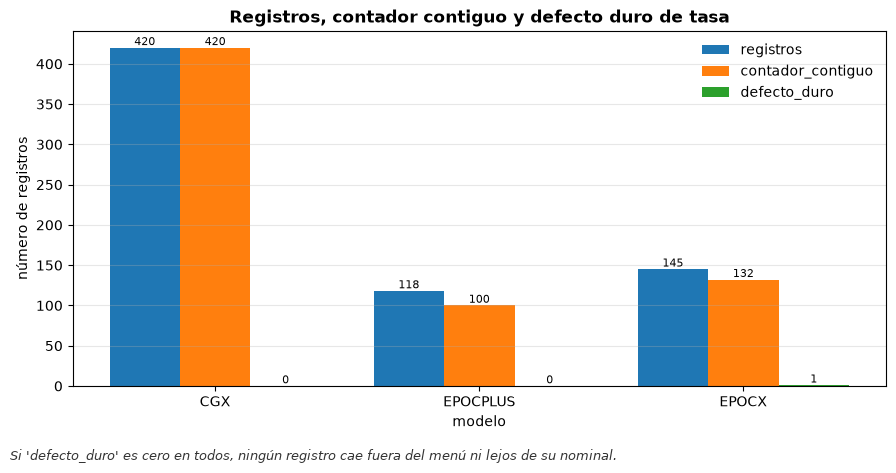

,registros,defecto_duro,contador_contiguo,mitad_de_la_nominal
device,,,,
CGX,420,0,420,0
EPOCPLUS,118,0,100,0
EPOCX,145,1,132,1


In [8]:
rate_tab = ok.groupby("device").agg(registros=("record_id", "count"),
    defecto_duro=("rate_hard_defect", "sum"),
    contador_contiguo=("counter_contiguous", "sum"),
    mitad_de_la_nominal=("half_of_nominal", "sum"))
fig = audit_plots.grouped_bar(rate_tab[["registros", "contador_contiguo", "defecto_duro"]],
    "Registros, contador contiguo y defecto duro de tasa", "modelo", "número de registros",
    "Si 'defecto_duro' es cero en todos, ningún registro cae fuera del menú ni lejos de su nominal.")
audit_plots.save(fig, "02_2.2_defecto_duro_tasa", FIG); plt.show()
rate_tab

## 2.3 Auditoría de integridad de muestras

Huecos (saltos del contador, leídos módulo su período) y muestras interpoladas por el propio dispositivo (solo Emotiv lo declara). El plan declara tres defectos; **solo uno tiene número**: un hueco contiguo más largo que una ventana (4 s, §3.1), que se marca. Los umbrales de fracción perdida y de fracción interpolada no están instanciados: se muestran sus distribuciones. El defecto es de segmento: se reporta cuántas ventanas toca, no un veredicto sobre el registro.

In [9]:
integ = ok.groupby("device").agg(
    registros=("record_id", "count"),
    con_alguna_perdida=("n_lost", lambda s: int((s > 0).sum())),
    fraccion_perdida_max=("lost_fraction", "max"),
    fraccion_perdida_mediana=("lost_fraction", "median"),
    con_interpolacion=("interpolated_fraction", lambda s: int((s > 0).sum())),
    fraccion_interpolada_mediana=("interpolated_fraction", "median"),
    fraccion_interpolada_max=("interpolated_fraction", "max"),
    hueco_mas_largo_s=("longest_gap_s", "max"),
    hueco_mayor_que_ventana=("gap_exceeds_window", "sum"))
integ

,registros,con_alguna_perdida,fraccion_perdida_max,fraccion_perdida_mediana,con_interpolacion,fraccion_interpolada_mediana,fraccion_interpolada_max,hueco_mas_largo_s,hueco_mayor_que_ventana
device,,,,,,,,,
CGX,420,0,0.000000,0.0,0,NaN,NaN,0.115066,0
EPOCPLUS,118,18,0.010131,0.0,118,0.004403,0.045526,9.838941,5
EPOCX,145,13,0.047318,0.0,39,0.000000,0.119212,28.820609,3


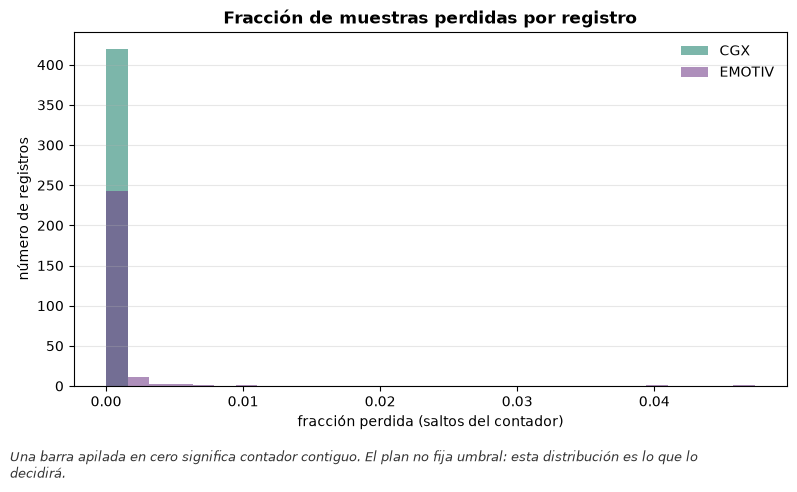

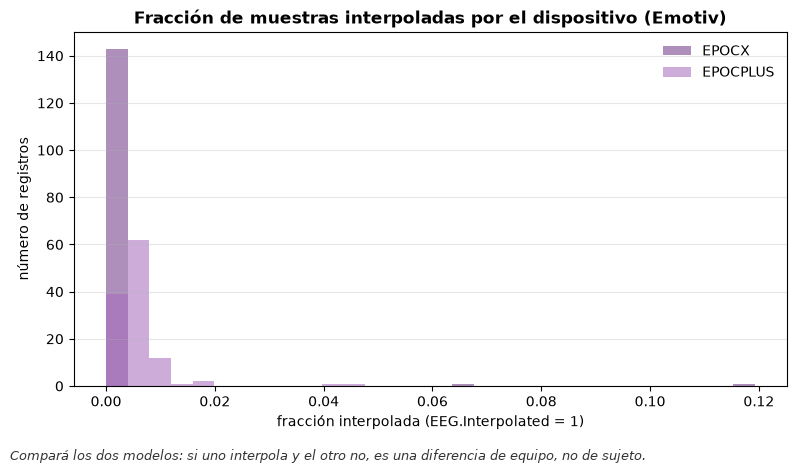

In [10]:
fig = audit_plots.hist(None, "Fracción de muestras perdidas por registro",
    "fracción perdida (saltos del contador)", "número de registros",
    "Una barra apilada en cero significa contador contiguo. El plan no fija umbral: esta distribución es lo que lo decidirá.",
    bins=30, groups={f: ok.loc[ok.family == f, "lost_fraction"] for f in ["CGX", "EMOTIV"]})
audit_plots.save(fig, "02_2.3_fraccion_perdida", FIG); plt.show()
em = ok[ok.family == "EMOTIV"]
fig = audit_plots.hist(None, "Fracción de muestras interpoladas por el dispositivo (Emotiv)",
    "fracción interpolada (EEG.Interpolated = 1)", "número de registros",
    "Compará los dos modelos: si uno interpola y el otro no, es una diferencia de equipo, no de sujeto.",
    bins=30, groups={d: em.loc[em.device == d, "interpolated_fraction"] for d in ["EPOCX", "EPOCPLUS"]})
audit_plots.save(fig, "02_2.3_fraccion_interpolada", FIG); plt.show()

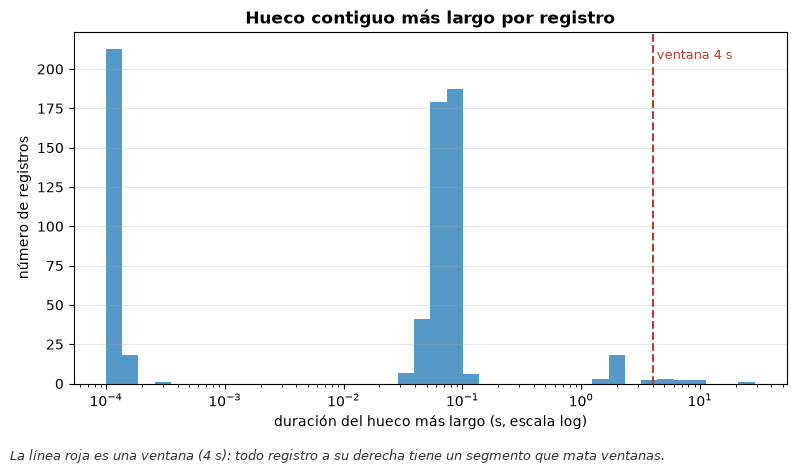

ventanas tocadas por pérdida, por registro (fracción):
          count      mean       std  min  50%       90%       99%       max
device                                                                     
CGX       420.0  0.000000  0.000000  0.0  0.0  0.000000  0.000000  0.000000
EPOCPLUS  118.0  0.002371  0.007685  0.0  0.0  0.004185  0.039738  0.041096
EPOCX     145.0  0.004279  0.028604  0.0  0.0  0.000000  0.144444  0.250000
ventanas tocadas por interpolación (Emotiv):
          count      mean       std       min       50%       90%       99%       max
device                                                                               
EPOCPLUS  118.0  0.366296  0.117134  0.028169  0.370136  0.473299  0.665114  0.833333
EPOCX     145.0  0.012196  0.066614  0.000000  0.000000  0.020202  0.279026  0.666667


In [11]:
fig = audit_plots.hist(ok["longest_gap_s"].clip(lower=1e-4), "Hueco contiguo más largo por registro",
    "duración del hueco más largo (s, escala log)", "número de registros",
    "La línea roja es una ventana (4 s): todo registro a su derecha tiene un segmento que mata ventanas.",
    bins=40, lines={"ventana 4 s": 4.0}, log_x=True)
audit_plots.save(fig, "02_2.3_hueco_mas_largo", FIG); plt.show()
touched = ok.assign(frac=ok["windows_touched_by_loss"] / ok["n_windows"])
print("ventanas tocadas por pérdida, por registro (fracción):")
print(touched.groupby("device")["frac"].describe(percentiles=[.5, .9, .99]))
if "windows_touched_by_interpolation" in ok:
    ti = em.assign(frac=em["windows_touched_by_interpolation"] / em["n_windows"])
    print("ventanas tocadas por interpolación (Emotiv):")
    print(ti.groupby("device")["frac"].describe(percentiles=[.5, .9, .99]))

## 2.4 Auditoría de canales

Primero la cabecera: número de canales por dispositivo y si los dos modelos Emotiv tienen el mismo montaje (el data paper lo afirma sin prueba). Después, por registro y canal: ausente frente a su cohorte, plano, saturado (alguna muestra en el riel del dispositivo), varianza fuera de rango frente a sus pares y sin contenido espectral en la banda.

**Marcar no es actuar**: no se interpola, no se quitan canales, no se excluyen registros. Los tres primeros criterios se marcan porque su definición no necesita un número. Los dos últimos no tienen corte declarado: se reporta un z robusto frente a los otros canales del mismo registro (log de la desviación estándar; fracción de potencia en banda por encima de 13 Hz) y no se marca nada.

In [12]:
chans = {(r["family"], r["device"]): r["channels"] for r in records if r.get("readable")}
for k, v in chans.items():
    print(k, len(v), "canales:", ", ".join(v))
emotiv_models = {d: c for (f, d), c in chans.items() if f == "EMOTIV"}
print("EPOC X y EPOC+ comparten montaje (mismos canales, mismo orden):", audit_channels.same_montage(emotiv_models))
counts = ok.groupby(["device", "n_channels"]).size().rename("registros")
print(counts)
print("registros con algún canal ausente frente a su cohorte:", int((ok["n_missing_vs_cohort"] > 0).sum()))

('EMOTIV', 'EPOCX') 14 canales: AF3, F7, F3, FC5, T7, P7, O1, O2, P8, T8, FC6, F4, F8, AF4
('CGX', 'CGX') 29 canales: AF7, Fpz, F7, Fz, T7, FC6, Fp1, F4, C4, Oz, CP6, Cz, PO8, CP5, O2, O1, P3, P4, P7, P8, Pz, PO7, T8, C3, Fp2, F3, F8, FC5, AF8
('EMOTIV', 'EPOCPLUS') 14 canales: AF3, F7, F3, FC5, T7, P7, O1, O2, P8, T8, FC6, F4, F8, AF4
EPOC X y EPOC+ comparten montaje (mismos canales, mismo orden): True
device    n_channels
CGX       29            420
EPOCPLUS  14            118
EPOCX     14            145
Name: registros, dtype: int64
registros con algún canal ausente frente a su cohorte: 0


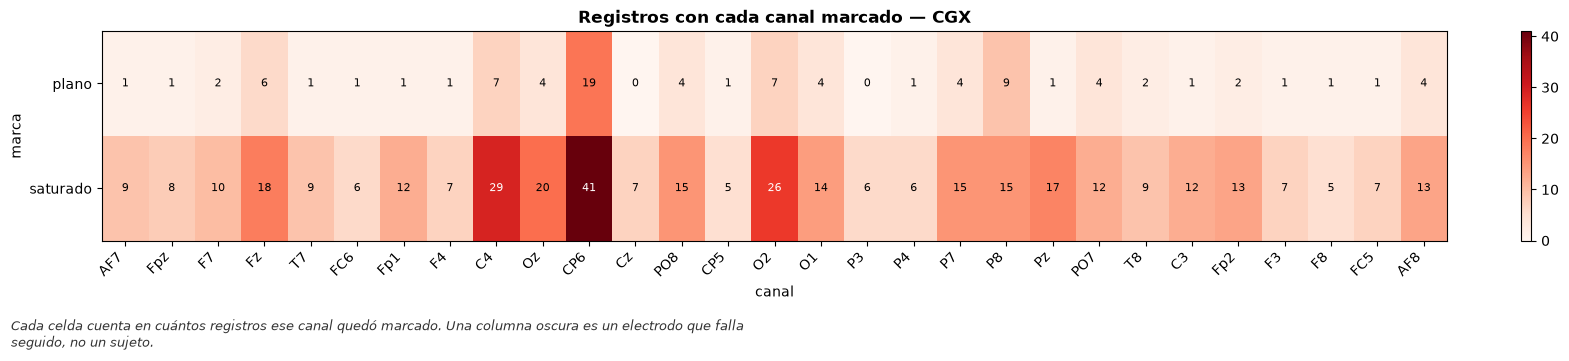

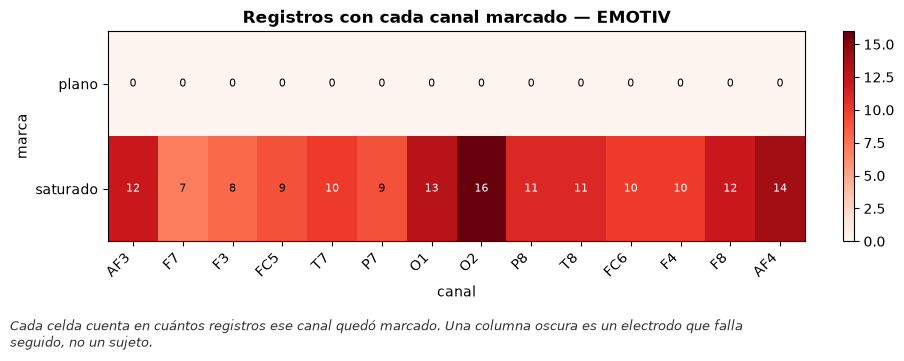

In [13]:
cc = chan.copy()
cc["flat"] = cc["marks"].str.contains("flat")
cc["saturated"] = cc["marks"].str.contains("saturated")
for family in ["CGX", "EMOTIV"]:
    sub = cc[cc.family == family]
    order = list(dict.fromkeys(sub["channel"]))
    heat = pd.DataFrame({"plano": sub.groupby("channel")["flat"].sum(),
                         "saturado": sub.groupby("channel")["saturated"].sum()}).loc[order].T
    fig = audit_plots.heatmap(heat, f"Registros con cada canal marcado — {family}", "canal", "marca",
        "Cada celda cuenta en cuántos registros ese canal quedó marcado. Una columna oscura es un electrodo que falla seguido, "
        "no un sujeto.", figsize=(min(16, 2 + 0.5 * len(order)), 3.2), cmap="Reds")
    audit_plots.save(fig, f"02_2.4_marcas_por_canal_{family}", FIG); plt.show()

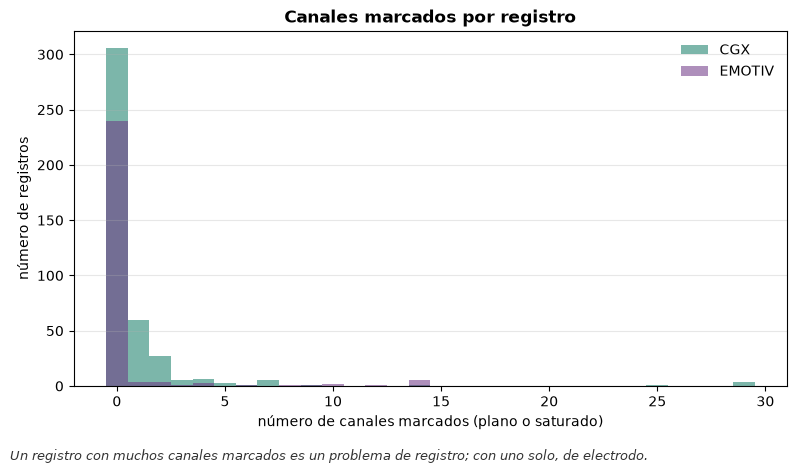

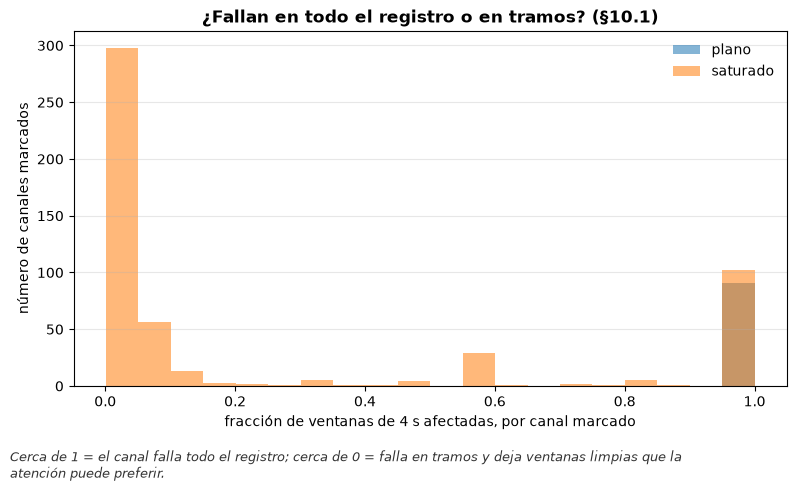

        canales_marcados  ventanas_saturadas_mediana  ventanas_planas_mediana
family                                                                       
CGX                  373                    0.078947                      0.0
EMOTIV               152                    0.006302                      0.0


In [14]:
fig = audit_plots.hist(None, "Canales marcados por registro", "número de canales marcados (plano o saturado)",
    "número de registros", "Un registro con muchos canales marcados es un problema de registro; con uno solo, de electrodo.",
    bins=np.arange(-0.5, max(2, ok["n_marked_channels"].max()) + 1.5, 1),
    groups={f: ok.loc[ok.family == f, "n_marked_channels"] for f in ["CGX", "EMOTIV"]})
audit_plots.save(fig, "02_2.4_canales_marcados_por_registro", FIG); plt.show()
marked = cc[cc["flat"] | cc["saturated"]]
fig = audit_plots.hist(None, "¿Fallan en todo el registro o en tramos? (§10.1)",
    "fracción de ventanas de 4 s afectadas, por canal marcado", "número de canales marcados",
    "Cerca de 1 = el canal falla todo el registro; cerca de 0 = falla en tramos y deja ventanas limpias que la atención puede preferir.",
    bins=20, groups={"plano": marked.loc[marked.flat, "flat_window_fraction"],
                     "saturado": marked.loc[marked.saturated, "saturated_window_fraction"]})
audit_plots.save(fig, "02_2.4_todo_o_tramos", FIG); plt.show()
print(marked.groupby(["family"]).agg(canales_marcados=("channel", "count"),
      ventanas_saturadas_mediana=("saturated_window_fraction", "median"),
      ventanas_planas_mediana=("flat_window_fraction", "median")))

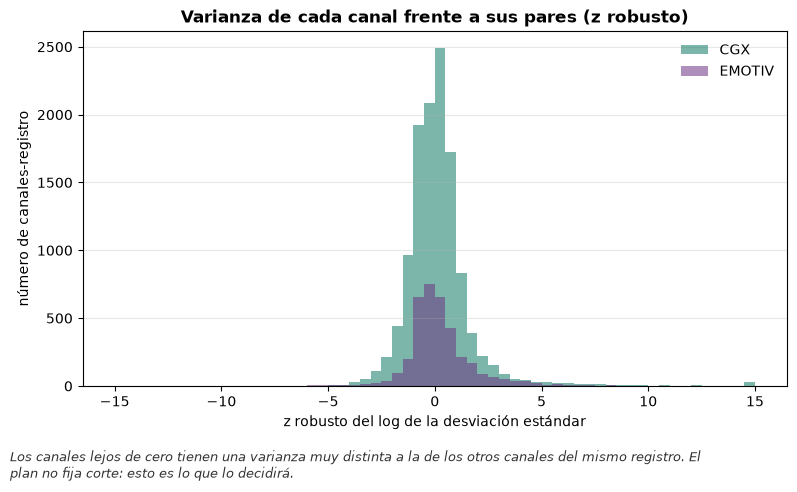

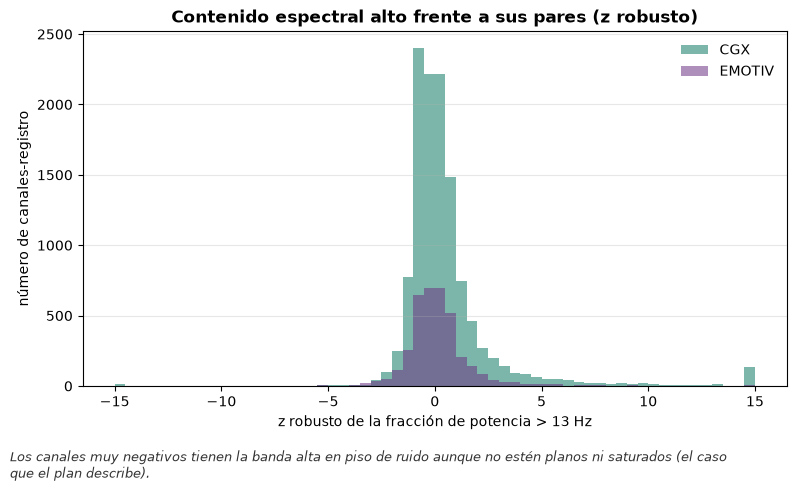

family                             CGX        EMOTIV
log_std_robust_z   count  12089.000000  3.682000e+03
                   mean       0.216274  2.083651e-01
                   std        4.753284  2.281344e+00
                   min      -65.760269 -6.657817e+01
                   1%        -2.942230 -4.779610e+00
                   5%        -1.747508 -1.727448e+00
                   50%        0.000000 -1.115278e-15
                   95%        2.403934  3.323892e+00
                   99%        6.886052  6.426423e+00
                   max      458.048031  2.311890e+01
high_band_robust_z count  12089.000000  3.682000e+03
                   mean       1.432363  1.966567e-01
                   std       33.175863  2.007472e+00
                   min     -205.728135 -1.348242e+01
                   1%        -2.416431 -3.211530e+00
                   5%        -1.343655 -1.742120e+00
                   50%        0.000000  0.000000e+00
                   95%        4.129795  2.6054

In [15]:
for key, title, xlabel, caption in [
    ("log_std_robust_z", "Varianza de cada canal frente a sus pares (z robusto)", "z robusto del log de la desviación estándar",
     "Los canales lejos de cero tienen una varianza muy distinta a la de los otros canales del mismo registro. El plan no fija corte: esto es lo que lo decidirá."),
    ("high_band_robust_z", "Contenido espectral alto frente a sus pares (z robusto)", "z robusto de la fracción de potencia > 13 Hz",
     "Los canales muy negativos tienen la banda alta en piso de ruido aunque no estén planos ni saturados (el caso que el plan describe).")]:
    fig = audit_plots.hist(None, title, xlabel, "número de canales-registro", caption, bins=60,
        groups={f: cc.loc[cc.family == f, key].clip(-15, 15) for f in ["CGX", "EMOTIV"]})
    audit_plots.save(fig, f"02_2.4_{key}", FIG); plt.show()
print(cc.groupby("family")[["log_std_robust_z", "high_band_robust_z"]].describe(percentiles=[.01, .05, .5, .95, .99]).T)

### Referencia mastoidea (A2) y canales externos bipolares (ExG) del CGX (§2.1, §10.1)

Si los canales ya vinieran referenciados a A2, su columna leería cerca de cero frente al cuero cabelludo. Si los ExG llevan señal ocular, correlacionan en baja frecuencia (0,2–4 Hz) más con los canales frontopolares que con los occipitales.

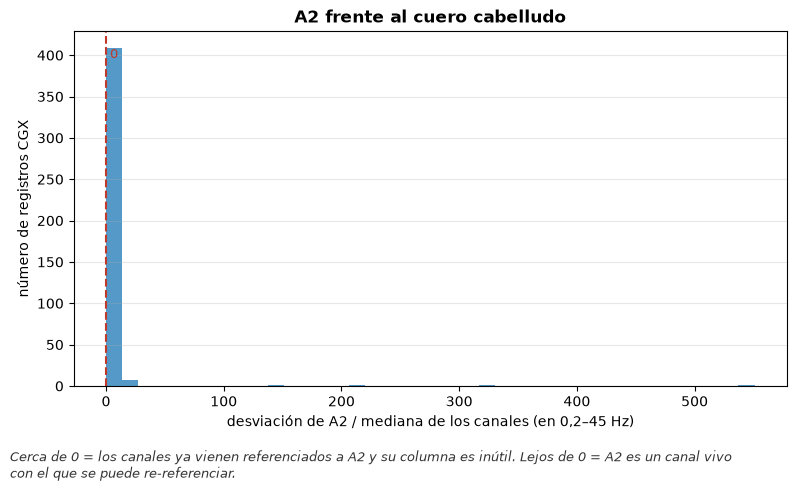

          a2_raw_std  a2_raw_median_abs  a2_band_std_ratio  a2_band_corr_scalp_mean
count     420.000000         420.000000         420.000000               420.000000
mean     4293.439095       25274.890214           4.076662                 0.314592
std     27040.663615       98397.296290          33.387567                 0.283301
min         0.000000          54.050554           0.027378                -0.270259
5%        129.364472         781.700595           0.237735                -0.017600
50%       656.603776        7933.434570           0.646072                 0.274668
95%      5662.675255       40972.006934           3.743635                 0.913376
max    427592.417288      833333.312500         550.935503                 0.999930


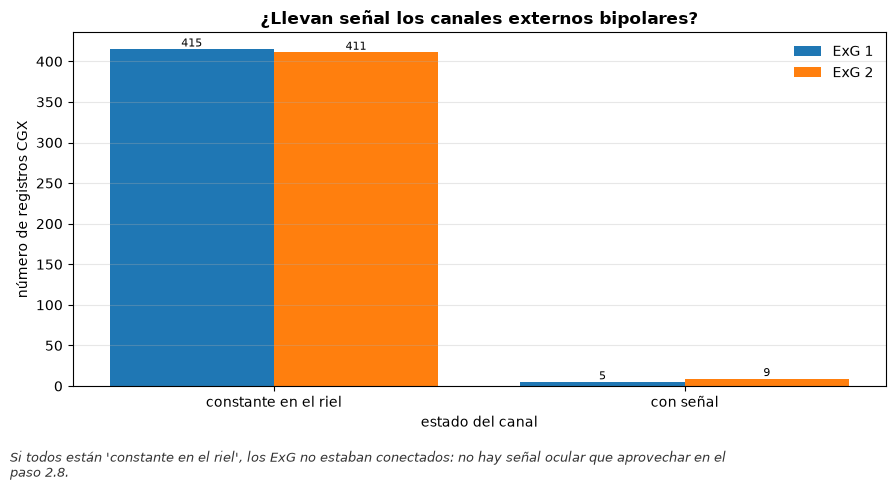

                      ExG 1  ExG 2
constante en el riel    415    411
con señal                 5      9
registros con algún ExG no constante: 9
                                   record_id  exg1_front_minus_back_corr  exg2_front_minus_back_corr
18   UB0022__SlacklineLvl11__1677863130__CGX                   -0.010468                    0.006887
122  UB0044__SlacklineLvl11__1685631200__CGX                    0.117700                    0.117953
182   UB0058__SlacklineLvl1__1686666394__CGX                         NaN                    0.003164
295  UB0084__SlacklineLvl11__1694449207__CGX                         NaN                    0.004069
296   UB0084__SlacklineLvl1__1694448355__CGX                         NaN                   -0.004245
297   UB0084__SlacklineLvl6__1694448775__CGX                         NaN                   -0.000735
335  UB0093__SlacklineLvl11__1695398244__CGX                   -0.022331                   -0.022172
621   UB0162__SlacklineLvl6__1721645560__CGX   

In [16]:
cg = ok[ok.family == "CGX"]
fig = audit_plots.hist(cg["a2_band_std_ratio"], "A2 frente al cuero cabelludo",
    "desviación de A2 / mediana de los canales (en 0,2–45 Hz)", "número de registros CGX",
    "Cerca de 0 = los canales ya vienen referenciados a A2 y su columna es inútil. Lejos de 0 = A2 es un canal vivo con el que se puede re-referenciar.",
    bins=40, lines={"0": 0.0})
audit_plots.save(fig, "02_2.4_referencia_A2", FIG); plt.show()
print(cg[["a2_raw_std", "a2_raw_median_abs", "a2_band_std_ratio", "a2_band_corr_scalp_mean"]].describe(percentiles=[.05, .5, .95]))
exg = pd.DataFrame({name: {"constante en el riel": int(cg[f"{key}_constant"].sum()),
                           "con señal": int((~cg[f"{key}_constant"].astype(bool)).sum())}
                    for name, key in (("ExG 1", "exg1"), ("ExG 2", "exg2"))})
fig = audit_plots.grouped_bar(exg, "¿Llevan señal los canales externos bipolares?", "estado del canal",
    "número de registros CGX",
    "Si todos están 'constante en el riel', los ExG no estaban conectados: no hay señal ocular que aprovechar en el paso 2.8.")
audit_plots.save(fig, "02_2.4_ExG", FIG); plt.show()
print(exg)
live = cg[~cg["exg1_constant"].astype(bool) | ~cg["exg2_constant"].astype(bool)]
print("registros con algún ExG no constante:", len(live))
if len(live):
    print(live[["record_id", "exg1_front_minus_back_corr", "exg2_front_minus_back_corr"]])

### ¿Los canales marcados se asocian con el diagnóstico? (§10.1)

Si los defectos de canal se asocian con la etiqueta, dejarlos pasar abre un atajo: el modelo aprendería ruido de contacto como predictor. Se cruza el número de canales marcados por registro (promediado por sujeto) contra diagnóstico, sexo y edad. Los indeterminados se muestran pero no entran a la prueba sí/no.

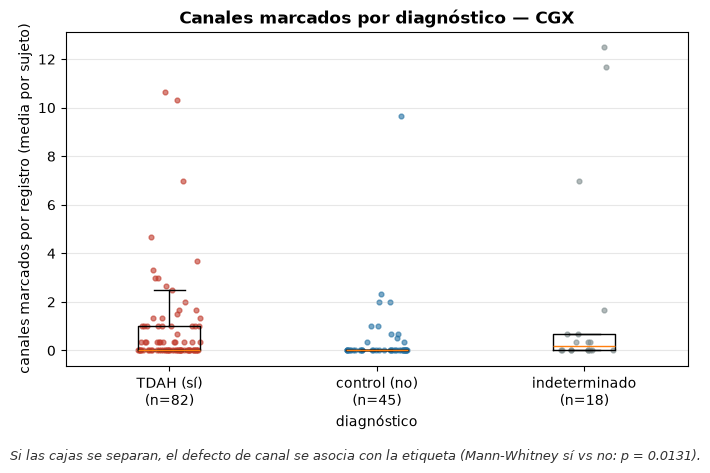

CGX sujetos con algún canal marcado, por diagnóstico:
       label  marked  total  unmarked  fraction_marked
          no      11     45        34         0.244444
undetermined       9     18         9         0.500000
         yes      39     82        43         0.475610
sex  marked  total  unmarked  fraction_marked
  F      19     54        35         0.351852
  M      40     91        51         0.439560
{'label_yes_vs_no_fisher_p': 0.013505772388654094, 'sex_fisher_p': 0.3821824188199896, 'age_mannwhitney_p': 0.0003729847889549403}


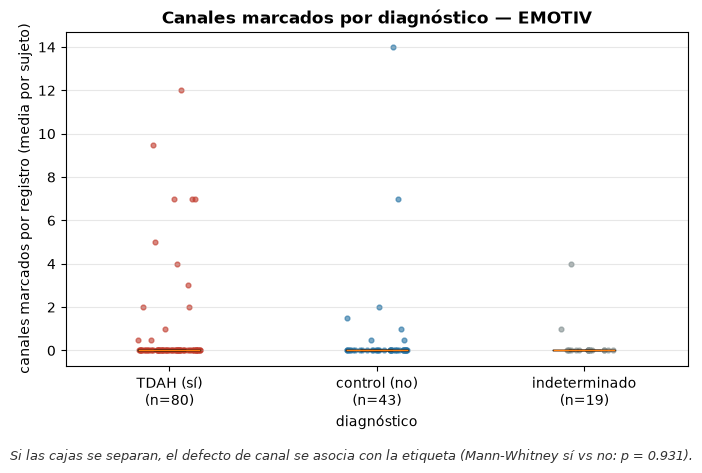

EMOTIV sujetos con algún canal marcado, por diagnóstico:
       label  marked  total  unmarked  fraction_marked
          no       7     43        36         0.162791
undetermined       2     19        17         0.105263
         yes      13     80        67         0.162500
sex  marked  total  unmarked  fraction_marked
  F       9     57        48         0.157895
  M      13     85        72         0.152941
{'label_yes_vs_no_fisher_p': 1.0, 'sex_fisher_p': 1.0, 'age_mannwhitney_p': 0.12375787548967454}


,familia,medida,n,median_yes,median_no,label_mannwhitney_p,median_M,median_F,sex_mannwhitney_p,age_spearman_rho,age_spearman_p
0,CGX,canales marcados por registro,145,0.0,0.0,0.013071,0.0,0.0,0.232246,-0.287405,0.000456
1,EMOTIV,canales marcados por registro,142,0.0,0.0,0.930919,0.0,0.0,0.863554,-0.152256,0.070472


In [17]:
cross_rows = []
for family in ["CGX", "EMOTIV"]:
    sub = ok[ok.family == family]
    per_subject = sub.groupby("subject")["n_marked_channels"].mean()
    res = defect_log.continuous_cross(per_subject, demo)
    cross_rows.append({"familia": family, "medida": "canales marcados por registro", **res})
    groups = {k: per_subject[per_subject.index.map(lab) == k] for k in ["yes", "no", "undetermined"]}
    fig = audit_plots.box_by_group(groups, f"Canales marcados por diagnóstico — {family}", "diagnóstico",
        "canales marcados por registro (media por sujeto)",
        f"Si las cajas se separan, el defecto de canal se asocia con la etiqueta (Mann-Whitney sí vs no: p = {res['label_mannwhitney_p']:.3g}).")
    audit_plots.save(fig, f"02_2.4_canales_marcados_por_diagnostico_{family}", FIG); plt.show()
    flags = defect_log.subject_flags(ok, family, ok["n_marked_channels"] > 0)
    cross = defect_log.cross_with_demographics(flags, demo)
    print(family, "sujetos con algún canal marcado, por diagnóstico:")
    print(cross["label"].to_string(index=False)); print(cross["sex"].to_string(index=False)); print(cross["tests"])
pd.DataFrame(cross_rows)

## 2.5 Auditoría de calidad de contacto

Asimétrica por necesidad. **Emotiv** trae calidad por canal y por sesión: el data paper declara como aceptable una calidad de señal no menor al 90 %. `EQ.OVERALL` es esa calidad de señal; `CQ.Overall` es la calidad de contacto (el semáforo verde del armado). Se mide la mediana y la fracción de ventanas de 4 s cuya mediana cae bajo 90; cómo agregar ventanas en un veredicto de registro no está declarado, así que no se excluye nada.

**CGX** no trae ninguna columna de calidad ni umbral: el criterio sale de la señal. Se mide la captación de red (potencia en 49–51 Hz sobre potencia en banda), porque un electrodo seco con mal contacto tiene impedancia alta y capta más 50 Hz. Sin corte.

Y la auditoría de la auditoría: ¿la calidad se asocia con la etiqueta? Un chico con el trastorno se mueve más.

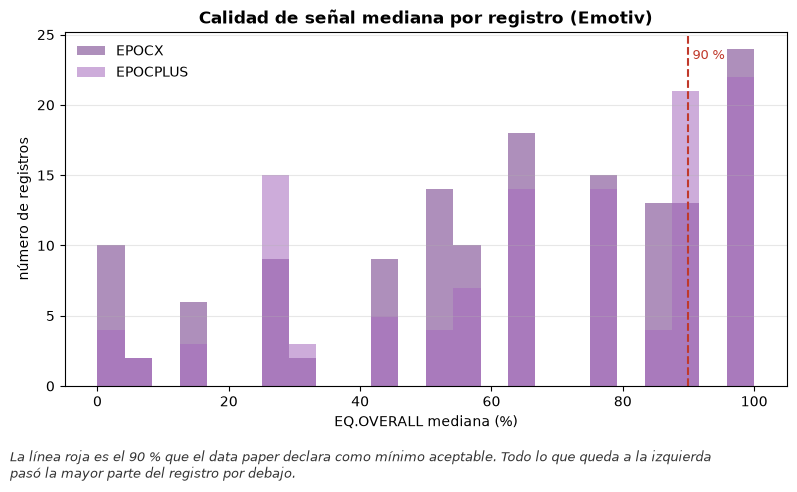

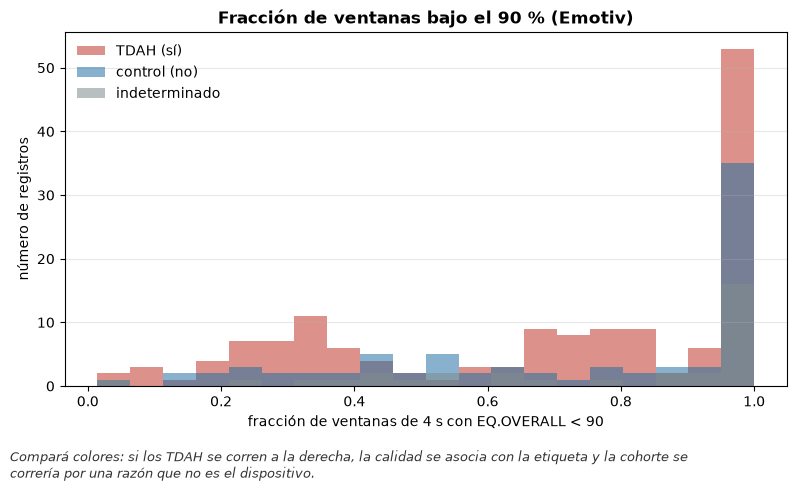

       eq_overall_median  eq_window_fraction_below  cq_overall_median  cq_window_fraction_below
count         263.000000                263.000000         263.000000                263.000000
mean           64.115969                  0.716622          86.311787                  0.347354
std            30.119436                  0.300445          24.335982                  0.447629
min             0.000000                  0.014493           0.000000                  0.000000
10%            18.333333                  0.260393          50.000000                  0.000000
50%            66.666664                  0.814737         100.000000                  0.001855
90%           100.000000                  1.000000         100.000000                  1.000000
max           100.000000                  1.000000         100.000000                  1.000000
registros Emotiv con alguna ventana bajo 90 (EQ): 263 de 263


In [18]:
em = ok[ok.family == "EMOTIV"]
fig = audit_plots.hist(None, "Calidad de señal mediana por registro (Emotiv)", "EQ.OVERALL mediana (%)",
    "número de registros", "La línea roja es el 90 % que el data paper declara como mínimo aceptable. Todo lo que queda a la izquierda pasó la mayor parte del registro por debajo.",
    bins=24, lines={"90 %": 90}, groups={d: em.loc[em.device == d, "eq_overall_median"] for d in ["EPOCX", "EPOCPLUS"]})
audit_plots.save(fig, "02_2.5_EQ_mediana", FIG); plt.show()
fig = audit_plots.hist(None, "Fracción de ventanas bajo el 90 % (Emotiv)", "fracción de ventanas de 4 s con EQ.OVERALL < 90",
    "número de registros", "Compará colores: si los TDAH se corren a la derecha, la calidad se asocia con la etiqueta y la cohorte se correría por una razón que no es el dispositivo.",
    bins=20, groups={k: em.loc[em.label == k, "eq_window_fraction_below"] for k in ["yes", "no", "undetermined"]})
audit_plots.save(fig, "02_2.5_ventanas_bajo_90_por_diagnostico", FIG); plt.show()
print(em[["eq_overall_median", "eq_window_fraction_below", "cq_overall_median", "cq_window_fraction_below"]].describe(percentiles=[.1, .5, .9]))
print("registros Emotiv con alguna ventana bajo 90 (EQ):", int(em["quality_any_window_below"].sum()), "de", len(em))

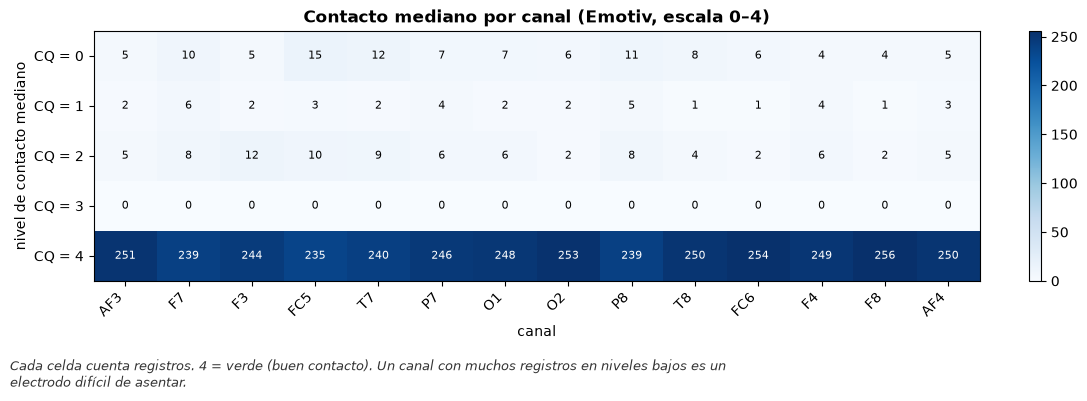

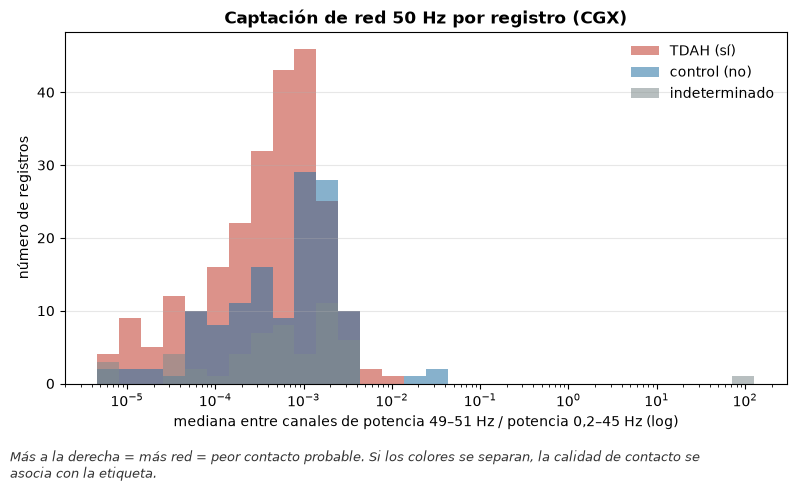

,familia,medida,n,median_yes,median_no,label_mannwhitney_p,median_M,median_F,sex_mannwhitney_p,age_spearman_rho,age_spearman_p
0,EMOTIV,eq_window_fraction_below,142,0.773178,0.768102,0.531617,0.753296,0.839011,0.055744,-0.169060,0.044297
1,EMOTIV,eq_overall_median,142,70.833333,66.666664,0.856744,70.833334,62.499998,0.067738,0.196774,0.018920
2,CGX,line_noise_median,145,0.000564,0.000913,0.078984,0.000663,0.000734,0.409892,0.326943,0.000060


In [19]:
per_ch = {}
for r in records:
    if r.get("readable") and r["family"] == "EMOTIV":
        per_ch[r["record_id"]] = r["contact"]["per_channel_contact_median"]
pc = pd.DataFrame(per_ch).T
level = pd.DataFrame({lvl: (pc == lvl).sum() for lvl in [0.0, 1.0, 2.0, 3.0, 4.0]}).T
level.index = [f"CQ = {int(v)}" for v in level.index]
fig = audit_plots.heatmap(level, "Contacto mediano por canal (Emotiv, escala 0–4)", "canal", "nivel de contacto mediano",
    "Cada celda cuenta registros. 4 = verde (buen contacto). Un canal con muchos registros en niveles bajos es un electrodo difícil de asentar.",
    figsize=(11, 3.6))
audit_plots.save(fig, "02_2.5_contacto_por_canal", FIG); plt.show()
cg = ok[ok.family == "CGX"]
fig = audit_plots.hist(None, "Captación de red 50 Hz por registro (CGX)", "mediana entre canales de potencia 49–51 Hz / potencia 0,2–45 Hz (log)",
    "número de registros", "Más a la derecha = más red = peor contacto probable. Si los colores se separan, la calidad de contacto se asocia con la etiqueta.",
    bins=30, log_x=True, groups={k: cg.loc[cg.label == k, "line_noise_median"] for k in ["yes", "no", "undetermined"]})
audit_plots.save(fig, "02_2.5_red_50Hz_CGX", FIG); plt.show()
rows = []
for family, column in (("EMOTIV", "eq_window_fraction_below"), ("EMOTIV", "eq_overall_median"), ("CGX", "line_noise_median")):
    sub = ok[ok.family == family]
    rows.append({"familia": family, "medida": column, **defect_log.continuous_cross(sub.groupby("subject")[column].mean(), demo)})
contact_cross = pd.DataFrame(rows)
contact_cross.to_csv(OUT / "contact_cross.csv", index=False)
contact_cross

## 2.6 Auditoría de duración

El plan declara tres defectos (truncada, reiniciada/concatenada, por debajo del piso de cardinalidad) pero **ninguno de sus tres números está instanciado**. Se reporta la duración real, su razón a la nominal y el número de ventanas completas de 4 s (las instancias que tendría la bolsa). Nominales: Slackline = último banderín + 2 s (del archivo de banderines); Robots = 14 filas × 20 s = 280 s (data paper); CogniFit no tiene nominal declarada (aplicación de terceros, sin flujo de eventos).

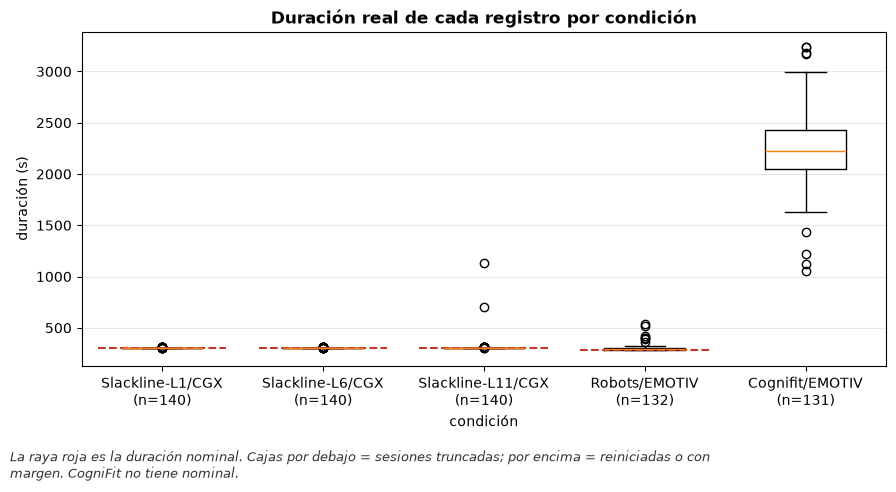

,registros,nominal_s,duracion_min,duracion_mediana,duracion_max,razon_mediana,ventanas_min,ventanas_mediana,ventanas_max
condition,,,,,,,,,
Slackline-L1/CGX,140,302.0,304.881624,304.999995,308.722042,1.009934,76,76.0,77
Slackline-L6/CGX,140,302.0,304.720917,305.000494,308.767738,1.009935,76,76.0,77
Slackline-L11/CGX,140,303.0,304.887894,305.001203,1134.796806,1.006605,76,76.0,283
Robots/EMOTIV,132,280.0,279.310374,292.982115,535.551533,1.046365,69,73.0,133
Cognifit/EMOTIV,131,NaN,1058.763163,2228.058269,3238.465770,NaN,264,557.0,809


In [20]:
order = ["Slackline-L1/CGX", "Slackline-L6/CGX", "Slackline-L11/CGX", "Robots/EMOTIV", "Cognifit/EMOTIV"]
groups = {c: ok.loc[ok.condition == c, "duration_s"] for c in order}
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([g.values for g in groups.values()], showfliers=True)
ax.set_xticks(range(1, 6), [f"{c}\n(n={len(g)})" for c, g in groups.items()])
for k, c in enumerate(order, start=1):
    nom = ok.loc[ok.condition == c, "nominal_s"].dropna()
    if len(nom):
        ax.hlines(nom.iloc[0], k - 0.4, k + 0.4, colors="#c0392b", linestyles="--")
audit_plots._finish(fig, ax, "Duración real de cada registro por condición", "condición", "duración (s)",
    "La raya roja es la duración nominal. Cajas por debajo = sesiones truncadas; por encima = reiniciadas o con margen. CogniFit no tiene nominal.")
audit_plots.save(fig, "02_2.6_duracion_por_condicion", FIG); plt.show()
dur = ok.groupby("condition").agg(registros=("record_id", "count"), nominal_s=("nominal_s", "first"),
    duracion_min=("duration_s", "min"), duracion_mediana=("duration_s", "median"), duracion_max=("duration_s", "max"),
    razon_mediana=("ratio_to_nominal", "median"), ventanas_min=("n_windows", "min"),
    ventanas_mediana=("n_windows", "median"), ventanas_max=("n_windows", "max")).loc[order]
dur.to_csv(OUT / "duration_by_condition.csv")
dur

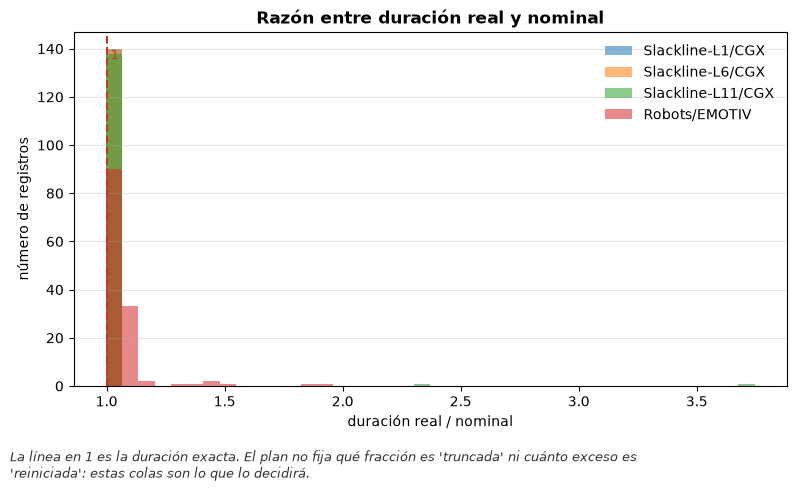

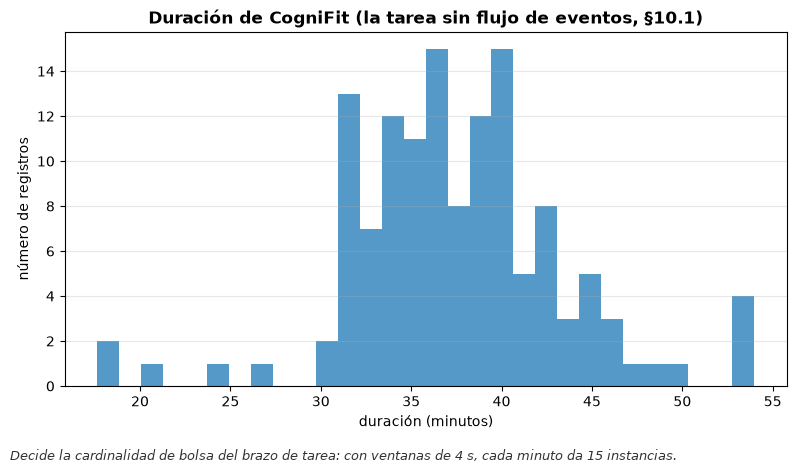

In [21]:
fig = audit_plots.hist(None, "Razón entre duración real y nominal", "duración real / nominal", "número de registros",
    "La línea en 1 es la duración exacta. El plan no fija qué fracción es 'truncada' ni cuánto exceso es 'reiniciada': estas colas son lo que lo decidirá.",
    bins=40, lines={"1": 1.0}, groups={c: ok.loc[ok.condition == c, "ratio_to_nominal"] for c in order[:4]})
audit_plots.save(fig, "02_2.6_razon_nominal", FIG); plt.show()
fig = audit_plots.hist(ok.loc[ok.condition == "Cognifit/EMOTIV", "duration_s"] / 60, "Duración de CogniFit (la tarea sin flujo de eventos, §10.1)",
    "duración (minutos)", "número de registros",
    "Decide la cardinalidad de bolsa del brazo de tarea: con ventanas de 4 s, cada minuto da 15 instancias.", bins=30)
audit_plots.save(fig, "02_2.6_duracion_cognifit", FIG); plt.show()

## 2.10 Registro de defectos

Tabla de flujo por cohorte de dispositivo, desde los sujetos iniciales, con el desglose por paso. `subjects_left` cuenta los sujetos que quedarían si se aplicaran **solo** los defectos duros cuya regla el plan declara completa (archivo ilegible; tasa fuera del menú o distinta de la nominal). Todas las demás columnas son marcas: no excluyen. Defectos duros e incompatibilidades (canal ausente frente a la cohorte) se reportan por separado, cada uno con su cruce contra diagnóstico, sexo y edad.

--- CGX
          step  records  records_marked  subjects_marked  records_hard_defect  subjects_left
       inicial      420               0                0                    0            145
       lectura      420               0                0                    0            145
      2.2 tasa      420               0                0                    0            145
2.3 integridad      420               0                0                    0            145
   2.4 canales      420             114               59                    0            145
  2.5 contacto      420               0                0                    0            145
  2.6 duración      420               0                0                    0            145
--- EMOTIV
          step  records  records_marked  subjects_marked  records_hard_defect  subjects_left
       inicial      263               0                0                    0            142
       lectura      263               0            

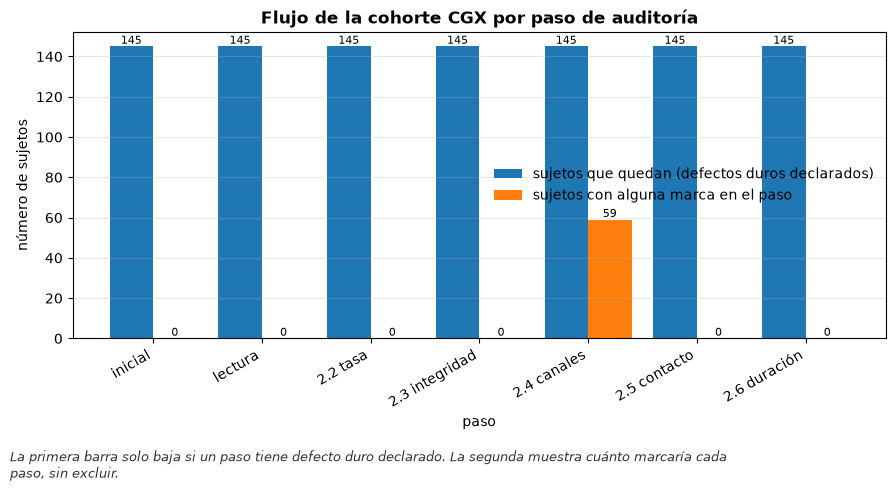

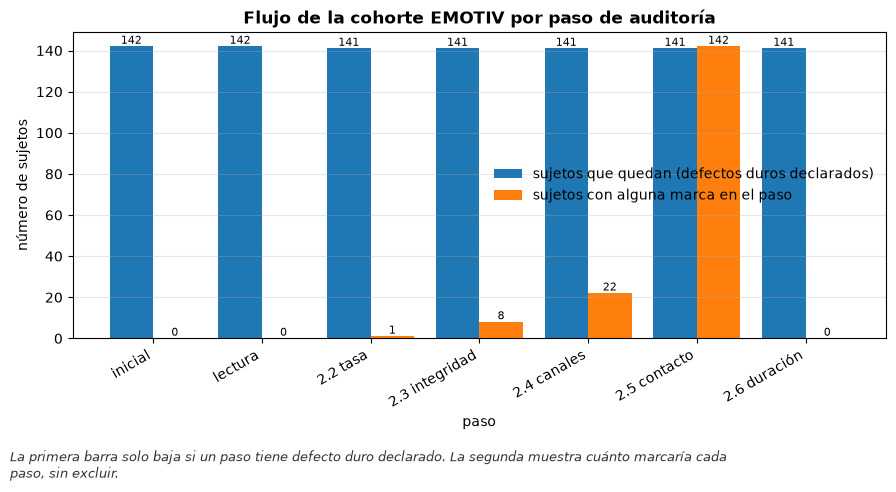

In [22]:
flows = {}
for family in ["CGX", "EMOTIV"]:
    flows[family] = defect_log.flow_table(rec, family)
    flows[family].to_csv(OUT / f"flow_{family}.csv", index=False)
    print(f"--- {family}"); print(flows[family].to_string(index=False))
for family, flow in flows.items():
    f = flow.set_index("step")
    fig = audit_plots.grouped_bar(f[["subjects_left", "subjects_marked"]].rename(columns={
        "subjects_left": "sujetos que quedan (defectos duros declarados)", "subjects_marked": "sujetos con alguna marca en el paso"}),
        f"Flujo de la cohorte {family} por paso de auditoría", "paso", "número de sujetos",
        "La primera barra solo baja si un paso tiene defecto duro declarado. La segunda muestra cuánto marcaría cada paso, sin excluir.")
    audit_plots.save(fig, f"02_2.10_flujo_{family}", FIG); plt.show()

In [23]:
rows, label_tables = [], {}
for family in ["CGX", "EMOTIV"]:
    sub = rec[rec.family == family]
    kinds = {"defecto duro": sub["hard_defects"].map(bool),
             "incompatibilidad": sub["incompatibilities"].map(bool)}
    for step, (marked, _) in defect_log.step_marks(sub).items():
        if marked.any():
            kinds[f"marca {step}"] = marked
    for kind, mask in kinds.items():
        flags = defect_log.subject_flags(rec.loc[sub.index], family, mask)
        cross = defect_log.cross_with_demographics(flags, demo)
        lt = cross["label"].set_index("label")
        label_tables[(family, kind)] = lt["fraction_marked"]
        rows.append({"familia": family, "tipo": kind, "sujetos_marcados": int(flags.sum()), "sujetos": int(len(flags)),
                     **{f"marcados_{k}": int(lt.loc[k, "marked"]) if k in lt.index else 0 for k in ["yes", "no", "undetermined"]},
                     **cross["tests"]})
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "defect_crosses.csv", index=False)
summary

,familia,tipo,sujetos_marcados,sujetos,marcados_yes,marcados_no,marcados_undetermined,label_yes_vs_no_fisher_p,sex_fisher_p,age_mannwhitney_p
0,CGX,defecto duro,0,145,0,0,0,1.000000,1.000000,NaN
1,CGX,incompatibilidad,0,145,0,0,0,1.000000,1.000000,NaN
2,CGX,marca 2.4 canales,59,145,39,11,9,0.013506,0.382182,0.000373
3,EMOTIV,defecto duro,1,142,1,0,0,1.000000,0.401408,0.815727
4,EMOTIV,incompatibilidad,0,142,0,0,0,1.000000,1.000000,NaN
5,EMOTIV,marca 2.2 tasa,1,142,1,0,0,1.000000,0.401408,0.815727
6,EMOTIV,marca 2.3 integridad,8,142,4,2,2,1.000000,1.000000,0.302066
7,EMOTIV,marca 2.4 canales,22,142,13,7,2,1.000000,1.000000,0.123758
8,EMOTIV,marca 2.5 contacto,142,142,80,43,19,1.000000,1.000000,NaN


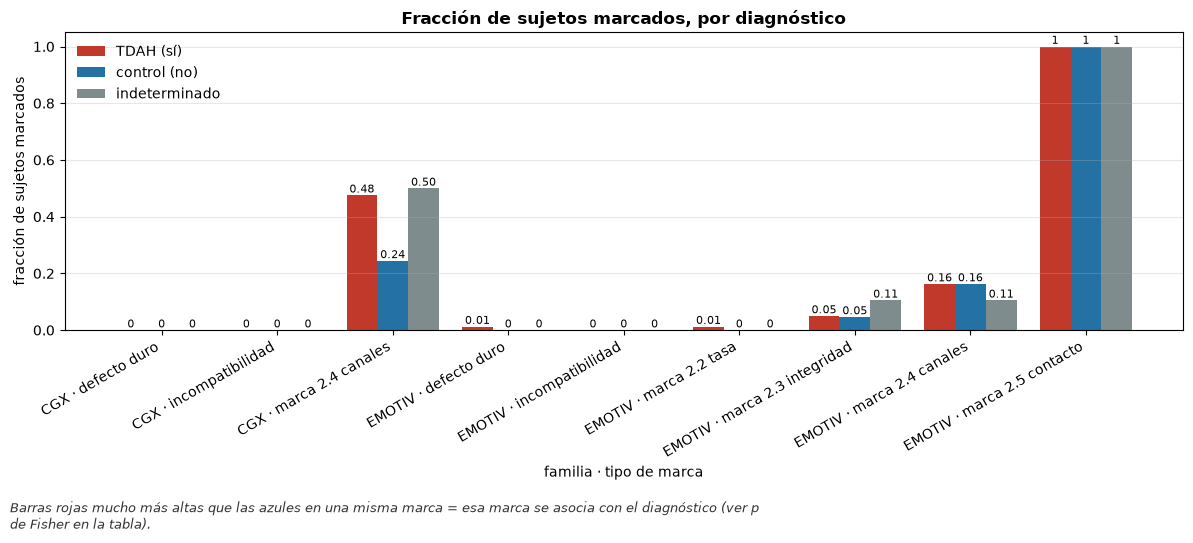

In [24]:
frac = pd.DataFrame(label_tables).T.reindex(columns=["yes", "no", "undetermined"]).fillna(0)
frac.index = [f"{f} · {k}" for f, k in frac.index]
fig = audit_plots.grouped_bar(frac, "Fracción de sujetos marcados, por diagnóstico", "familia · tipo de marca",
    "fracción de sujetos marcados", "Barras rojas mucho más altas que las azules en una misma marca = esa marca se asocia con el diagnóstico (ver p de Fisher en la tabla).",
    figsize=(12, 5))
audit_plots.save(fig, "02_2.10_marcas_por_diagnostico", FIG); plt.show()

## Lo que esta auditoría contesta de §10.1

Cada línea sale de los números de arriba; nada se escribe a mano.

In [25]:
eeg = inventory.eeg_records(inventory.build_index(RAW))
overlap = inventory.condition_overlap(eeg)
cog = ok[ok.condition == "Cognifit/EMOTIV"]["duration_s"]
em_rates = ok[ok.family == "EMOTIV"].groupby(["device", "nominal_rate"]).size()
und = inventory.indeterminate_summary(demo)
cg = ok[ok.family == "CGX"]
def _bad_channel_totals(fam, marked):
    """Bad channels as record-channel pairs, each count shown against its total."""
    allc = cc[cc.family == fam]
    dead = marked[(marked.saturated & (marked.saturated_window_fraction == 1)) | marked.flat]
    pct = lambda n, d: f"{n} de {d} ({100 * n / d:.1f} %)"
    return (f"{fam}: pares registro-canal marcados {pct(len(marked), len(allc))}; "
            f"mediana de ventanas saturadas {marked.loc[marked.saturated, 'saturated_window_fraction'].median():.3f}; "
            f"pares que fallan en todas las ventanas {pct(len(dead), len(allc))}, "
            f"en {pct(dead.record_id.nunique(), allc.record_id.nunique())} registros "
            f"y {pct(dead.subject.nunique(), allc.subject.nunique())} sujetos")
answers = [
    ("Duración de la tarea sin flujo de eventos (CogniFit)", f"mediana {cog.median()/60:.1f} min, rango {cog.min()/60:.1f}–{cog.max()/60:.1f} min (n={len(cog)})"),
    ("Duración real de cada registro", "tabla por condición en 2.6 (`duration_by_condition.csv`), por registro en `records.csv`"),
    ("Solapamiento de sujetos entre condiciones", "matriz en 01 (`condition_overlap.csv`); CGX∩Robots = " + str(int(overlap.loc['Slackline-L1/CGX', 'Robots/EMOTIV'])) + ", Robots∩Cognifit = " + str(int(overlap.loc['Robots/EMOTIV', 'Cognifit/EMOTIV']))),
    ("Tasa real del Emotiv y si sus dos modelos coinciden", "; ".join(f"{d} {int(r)} Hz: {n}" for (d, r), n in em_rates.items())),
    ("Lista de canales del CGX y su número", f"{len(chans[('CGX', 'CGX')])} de cuero cabelludo + A2 + ExG 1/2"),
    ("Sujetos con diagnóstico indeterminado y su grupo", f"{und['count']} sujetos, grupo {und['by_group']}"),
    ("Varianza de la referencia mastoidea", f"desviación de A2 / mediana de los canales (0,2–45 Hz): mediana {cg['a2_band_std_ratio'].median():.2f}, p5 {cg['a2_band_std_ratio'].quantile(.05):.2f}, mínimo {cg['a2_band_std_ratio'].min():.2f}. Lejos de cero en casi todos: A2 es un canal vivo, los canales no vienen referenciados a él"),
    ("¿Los ExG llevan señal ocular?", f"ExG 1 constante en el riel en {int(cg['exg1_constant'].sum())}/{len(cg)} registros, ExG 2 en {int(cg['exg2_constant'].sum())}/{len(cg)}"),
    ("Canales defectuosos: ¿todo el registro o tramos?", "; ".join(_bad_channel_totals(f, g) for f, g in cc[cc.flat | cc.saturated].groupby("family"))),
    ("¿Registros a los que les falta un canal del montaje?", f"{int((ok['n_missing_vs_cohort'] > 0).sum())} registros"),
    ("¿Los canales defectuosos se asocian con el diagnóstico?", "; ".join(f"{r.familia}: sujetos marcados sí {r.marcados_yes} / no {r.marcados_no}, Fisher sí-vs-no p={r.label_yes_vs_no_fisher_p:.3g}, sexo p={r.sex_fisher_p:.3g}, edad p={r.age_mannwhitney_p:.3g}" for r in summary[summary.tipo == "marca 2.4 canales"].itertuples())),
    ("Corte numérico del filtro digital del fabricante", "NO medido en esta fase: requiere la densidad espectral por registro, fuera del alcance de la auditoría 2.1–2.6"),
]
answers = pd.DataFrame(answers, columns=["pendiente §10.1", "respuesta medida"])
answers.to_csv(OUT / "answers_10_1.csv", index=False)
with pd.option_context("display.max_colwidth", 200):
    display(answers)

,pendiente §10.1,respuesta medida
0,Duración de la tarea sin flujo de eventos (CogniFit),"mediana 37.1 min, rango 17.6–54.0 min (n=131)"
1,Duración real de cada registro,"tabla por condición en 2.6 (`duration_by_condition.csv`), por registro en `records.csv`"
2,Solapamiento de sujetos entre condiciones,"matriz en 01 (`condition_overlap.csv`); CGX∩Robots = 118, Robots∩Cognifit = 121"
3,Tasa real del Emotiv y si sus dos modelos coinciden,EPOCPLUS 128 Hz: 111; EPOCPLUS 256 Hz: 7; EPOCX 128 Hz: 145
4,Lista de canales del CGX y su número,29 de cuero cabelludo + A2 + ExG 1/2
5,Sujetos con diagnóstico indeterminado y su grupo,"20 sujetos, grupo {'2': 20}"
6,Varianza de la referencia mastoidea,"desviación de A2 / mediana de los canales (0,2–45 Hz): mediana 0.65, p5 0.24, mínimo 0.03. Lejos de cero en casi todos: A2 es un canal vivo, los canales no vienen referenciados a él"
7,¿Los ExG llevan señal ocular?,"ExG 1 constante en el riel en 415/420 registros, ExG 2 en 411/420"
8,Canales defectuosos: ¿todo el registro o tramos?,"CGX: pares registro-canal marcados 373 de 12180 (3.1 %); mediana de ventanas saturadas 0.079; pares que fallan en todas las ventanas 101 de 12180 (0.8 %), en 52 de 420 (12.4 %) registros y 23 de 1..."
9,¿Registros a los que les falta un canal del montaje?,0 registros
